In [1]:
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np


In [2]:
df=pd.read_csv('CreditScoring.csv')

In [3]:
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [4]:
df.columns=df.columns.str.lower()

In [5]:
# df.status=df.status.map({1:'ok',2:'default',0:'unk'})

In [6]:
status_values={1:'ok',
               2:'default',
               0:'unk'
}
df.status=df.status.map(status_values)

In [7]:
home_values={
    1:'rent',
    2:'owner',
    3:'private',
    4:'ignore',
    5:'parents',
    6:'other',
    0:'unk'
}
df.home=df.home.map(home_values)

In [8]:
marital_values={
    1:'single',
    2:'married',
    3:'widow',
    4:'seprated',
    5:'divorced',
    0:'unk'
}
df.marital=df.marital.map(marital_values)

In [9]:
records_values={
    1:'no',
    2:'yes',
    0:'unk'
}
df.records=df.records.map(records_values)

In [10]:
job_values={
    1:'fixed',
    2:'partime',
    3:'freelance',
    4:'other',
    0:'unk'
}
df.job=df.job.map(job_values)

In [11]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [12]:
for c in['income','assets','debt']:
    df[c]=df[c].replace(to_replace=99999999,value=np.nan)


In [13]:
df.status.value_counts()

status
ok         3200
default    1254
unk           1
Name: count, dtype: int64

In [14]:
df=df[df.status != 'unk'].reset_index(drop=True)


In [15]:
df_train_full ,df_test=train_test_split(df,test_size=0.2,random_state=11)
df_train ,df_val=train_test_split(df_train_full,test_size=0.25,random_state=11)


In [16]:
len(df_train),len(df_test),len(df_val)

(2672, 891, 891)

In [17]:
df_train=df_train.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)

In [ ]:
y_train=(df_train.status=='default').astype('int').values
y_val=(df_val.status=='default').astype('int').values
y_test=(df_test.status=='default').astype('int').values

In [19]:
del df_train['status']
del df_val['status']
del df_test['status']

In [20]:
df_train.head()

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,10,owner,36,36,married,no,freelance,75,0.0,10000.0,0.0,1000,1400
1,6,parents,48,32,single,yes,fixed,35,85.0,0.0,0.0,1100,1330
2,1,parents,48,40,married,no,fixed,75,121.0,0.0,0.0,1320,1600
3,1,parents,48,23,single,no,partime,35,72.0,0.0,0.0,1078,1079
4,5,owner,36,46,married,no,freelance,60,100.0,4000.0,0.0,1100,1897


In [21]:
my_df=df
my_df['status']=(my_df['status']=='default').astype(int).values


In [22]:
global_status=my_df['status'].mean()
global_status
category=my_df.columns[my_df.dtypes=='object']
category
my_df.home.unique()

array(['rent', 'owner', 'parents', 'private', 'other', 'ignore', 'unk'],
      dtype=object)

In [23]:
for t in my_df[category]:
 for i in my_df[t].unique():
   pro=my_df[my_df[t]==i].status.mean()
   print(t,i , pro/global_status)
my_df.marital.isnull().sum()

home rent 1.416353178564462
home owner 0.657434888943894
home parents 1.0569314846386835
home private 1.212821410510756
home other 1.6256043357181784
home ignore 1.5983253588516746
home unk 2.3678894205209993
marital married 0.9085067863060361
marital widow 1.0072365445499774
marital single 1.192427425687136
marital seprated 1.7485952643847382
marital divorced 1.308570469235289
marital unk 0.0
records no 0.796050844307182
records yes 1.9711990195410907
job freelance 1.1550398101076556
job fixed 0.7344255956696149
job partime 2.1295288704464297
job unk 3.5518341307814993
job other 1.412425268380947


np.int64(0)

In [24]:
def assess_risk(client):
    if client['records']=='yes':
        if client['job']=='parttime':
            return'default'
        else:
            return 'ok'
    else:
        if client['assets']>6000:
            return 'ok'
        else:
            return'default'



In [25]:
assess_risk(df_train.iloc[0].to_dict())

'ok'

In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score

In [27]:
train_dicts=df_train.fillna(0).to_dict(orient='records')
train_dicts
val_dicts=df_val.fillna(0).to_dict(orient='records')
val_dicts

[{'seniority': 6,
  'home': 'rent',
  'time': 36,
  'age': 31,
  'marital': 'seprated',
  'records': 'no',
  'job': 'fixed',
  'expenses': 49,
  'income': 140.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 550,
  'price': 999},
 {'seniority': 18,
  'home': 'rent',
  'time': 60,
  'age': 38,
  'marital': 'married',
  'records': 'no',
  'job': 'fixed',
  'expenses': 56,
  'income': 108.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 1000,
  'price': 1307},
 {'seniority': 17,
  'home': 'rent',
  'time': 24,
  'age': 40,
  'marital': 'married',
  'records': 'yes',
  'job': 'fixed',
  'expenses': 58,
  'income': 128.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 700,
  'price': 982},
 {'seniority': 2,
  'home': 'other',
  'time': 48,
  'age': 29,
  'marital': 'married',
  'records': 'no',
  'job': 'fixed',
  'expenses': 75,
  'income': 96.0,
  'assets': 6000.0,
  'debt': 3000.0,
  'amount': 1200,
  'price': 1521},
 {'seniority': 25,
  'home': 'rent',
  'time': 42,
  'age': 61,
  'marital': '

In [ ]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

depth_scores = []

for i in range(1, 10):
    dt = DecisionTreeClassifier(max_depth=i)
    dt.fit(X_train, y_train)
    val_pred = dt.predict_proba(X_val)[:, 1]
    train_pred = dt.predict_proba(X_train)[:, 1]
    
    val_auc = roc_auc_score(y_val, val_pred)
    train_auc = roc_auc_score(y_train, train_pred)
    inc = val_auc / train_auc
    
    print(i)
    print('val ', val_auc)
    print('train ', train_auc)
    print('the inc ', inc)
    
    depth_scores.append((i, val_auc, train_auc, inc))




1
val  0.6058644740984719
train  0.6282660131823559
the inc  0.9643438629277216
2
val  0.6685264343319367
train  0.7054989859726213
the inc  0.947593756510205
3
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
4
val  0.7612827250490422
train  0.8164293560926146
the inc  0.9324538851622127
5
val  0.7669377103969388
train  0.8433781899611289
the inc  0.9093639360442636
6
val  0.7619487297474026
train  0.8745461523294462
the inc  0.8712504511258456
7
val  0.7488163280133685
train  0.9000637288040111
the inc  0.8319592313850738
8
val  0.7411845196289748
train  0.9245169286237396
the inc  0.8016992406318851
9
val  0.6921241917124799
train  0.9475779533547406
the inc  0.7304139878541184


In [29]:
max_leaf_scores = []

for i in range(5,100,5):
    dt = DecisionTreeClassifier(max_depth=3,max_leaf_nodes=i)
    dt.fit(X_train, y_train)
    val_pred = dt.predict_proba(X_val)[:, 1]
    train_pred = dt.predict_proba(X_train)[:, 1]
    
    val_auc = roc_auc_score(y_val, val_pred)
    train_auc = roc_auc_score(y_train, train_pred)
    inc = val_auc / train_auc
    
    print(i)
    print('val ', val_auc)
    print('train ', train_auc)
    print('the inc ', inc)
    
    max_leaf_scores.append((i, val_auc, train_auc, inc))

    # the best is 3 max_depth and 10 max_leaf_nodes


5
val  0.7336859121842532
train  0.764551292884908
the inc  0.9596294179502471
10
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
15
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
20
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
25
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
30
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
35
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
40
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
45
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
50
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
55
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
60
val  0.7389079944782155
train  0.7761016984958594
the inc  0.9520762496851535
65
val  0.7389079944782155
tra

In [30]:
from sklearn.tree import export_text
print(export_text(dt,feature_names=dv.feature_names_))

|--- records=yes <= 0.50
|   |--- job=partime <= 0.50
|   |   |--- income <= 74.50
|   |   |   |--- class: 0
|   |   |--- income >  74.50
|   |   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- assets <= 8750.00
|   |   |   |--- class: 1
|   |   |--- assets >  8750.00
|   |   |   |--- class: 0
|--- records=yes >  0.50
|   |--- seniority <= 6.50
|   |   |--- amount <= 862.50
|   |   |   |--- class: 0
|   |   |--- amount >  862.50
|   |   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- income <= 103.50
|   |   |   |--- class: 1
|   |   |--- income >  103.50
|   |   |   |--- class: 0



In [31]:
for d in [1,2,3,4,5,6,10,15,20,None]:
    dt=DecisionTreeClassifier(max_depth=d)
    dt.fit(X_train,y_train)
    pred=dt.predict_proba(X_val)[:,1]
    auc=roc_auc_score(y_val,pred)
    print('%4s -> %.3f' % (d,auc))

   1 -> 0.606
   2 -> 0.669
   3 -> 0.739
   4 -> 0.761
   5 -> 0.767
   6 -> 0.745
  10 -> 0.704
  15 -> 0.659
  20 -> 0.662
None -> 0.673


In [32]:
scores=[]
for d in [4,5,6,7,10,12,None]:
    for s in [1,2,3,4,10,15,20,40,100,500]:
        dt=DecisionTreeClassifier(max_depth=d,min_samples_leaf=s)
        dt.fit(X_train,y_train)
        pred=dt.predict_proba(X_val)[:,1]
        auc=roc_auc_score(y_val,pred)
        scores.append((d,s,auc))
        print('(%4s , %3d) -> %.3f' % (d,s,auc))


(   4 ,   1) -> 0.761
(   4 ,   2) -> 0.761
(   4 ,   3) -> 0.761
(   4 ,   4) -> 0.761
(   4 ,  10) -> 0.761
(   4 ,  15) -> 0.764
(   4 ,  20) -> 0.761
(   4 ,  40) -> 0.753
(   4 , 100) -> 0.756
(   4 , 500) -> 0.680
(   5 ,   1) -> 0.766
(   5 ,   2) -> 0.766
(   5 ,   3) -> 0.767
(   5 ,   4) -> 0.766
(   5 ,  10) -> 0.762
(   5 ,  15) -> 0.772
(   5 ,  20) -> 0.774
(   5 ,  40) -> 0.767
(   5 , 100) -> 0.763
(   5 , 500) -> 0.680
(   6 ,   1) -> 0.744
(   6 ,   2) -> 0.767
(   6 ,   3) -> 0.748
(   6 ,   4) -> 0.762
(   6 ,  10) -> 0.778
(   6 ,  15) -> 0.786
(   6 ,  20) -> 0.774
(   6 ,  40) -> 0.770
(   6 , 100) -> 0.776
(   6 , 500) -> 0.680
(   7 ,   1) -> 0.736
(   7 ,   2) -> 0.760
(   7 ,   3) -> 0.748
(   7 ,   4) -> 0.758
(   7 ,  10) -> 0.763
(   7 ,  15) -> 0.780
(   7 ,  20) -> 0.781
(   7 ,  40) -> 0.779
(   7 , 100) -> 0.780
(   7 , 500) -> 0.680
(  10 ,   1) -> 0.686
(  10 ,   2) -> 0.705
(  10 ,   3) -> 0.722
(  10 ,   4) -> 0.726
(  10 ,  10) -> 0.766
(  10 ,  1

In [33]:
columns=['depth','min_simples_leaf','auc']
df_scores=pd.DataFrame(scores,columns=columns)
df_scores.head()

,depth,min_simples_leaf,auc
0,4.0,1,0.761283
1,4.0,2,0.761283
2,4.0,3,0.761283
3,4.0,4,0.761283
4,4.0,10,0.761283


In [34]:
df_scores.sort_values(by='auc',ascending=False).head()

,depth,min_simples_leaf,auc
45,10.0,15,0.788589
65,NaN,15,0.787759
46,10.0,20,0.787526
55,12.0,15,0.787320
25,6.0,15,0.785695


In [35]:
df_scores_pivot=df_scores.pivot(index='min_simples_leaf',columns=['depth'],values=['auc'])
df_scores_pivot.round(3)

auc                                          
depth               NaN   4.0    5.0    6.0    7.0    10.0   12.0
min_simples_leaf                                                 
1                 0.652  0.761  0.766  0.744  0.736  0.686  0.665
2                 0.690  0.761  0.766  0.767  0.760  0.705  0.701
3                 0.709  0.761  0.767  0.748  0.748  0.722  0.726
4                 0.710  0.761  0.766  0.762  0.758  0.726  0.713
10                0.758  0.761  0.762  0.778  0.763  0.766  0.763
15                0.788  0.764  0.772  0.786  0.780  0.789  0.787
20                0.782  0.761  0.774  0.774  0.781  0.788  0.784
40                0.782  0.753  0.767  0.770  0.779  0.782  0.782
100               0.780  0.756  0.763  0.776  0.780  0.780  0.780
500               0.680  0.680  0.680  0.680  0.680  0.680  0.680

<Axes: xlabel='None-depth', ylabel='min_simples_leaf'>

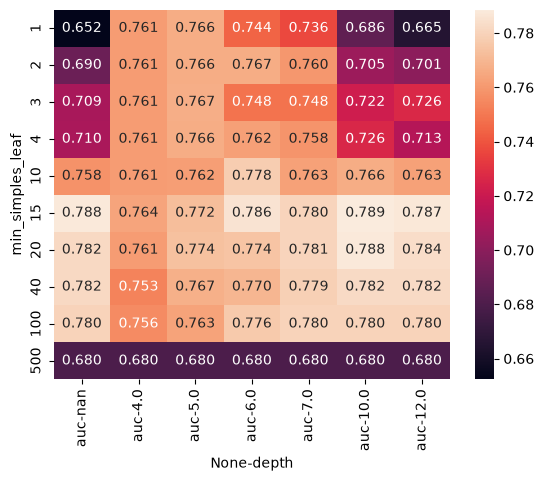

In [36]:
import seaborn as sns
sns.heatmap(df_scores_pivot,annot=True,fmt='.3f')

In [37]:

test_dicts=df_test.fillna(0).to_dict(orient='records')
X_test=dv.transform(test_dicts)
dt=DecisionTreeClassifier(max_depth=10,min_samples_leaf=15)
dt.fit(X_train,y_train)
pred=dt.predict_proba(X_test)[:,1]
auc=roc_auc_score(y_test,pred)
auc

0.7751637261130933

In [38]:
from sklearn.ensemble import RandomForestClassifier

In [39]:
rf=RandomForestClassifier(n_estimators=10,random_state=1)
rf.fit(X_train,y_train)
y_pred=rf.predict_proba(X_val)[:,1]
roc_auc_score(y_val,y_pred)

0.7744726453706618

In [40]:
scores=[]
for n in range(10,201,10):
    rf=RandomForestClassifier(n_estimators=n,random_state=1)
    rf.fit(X_train,y_train)
    y_pred=rf.predict_proba(X_val)[:,1]
    auc=roc_auc_score(y_val,y_pred)
    scores.append((n,auc))


In [41]:
df_scoresrf=pd.DataFrame(scores,columns=['n_estimators','auc'])
df_scoresrf.sort_values(by='auc',ascending=False)

,n_estimators,auc
19,200,0.819050
12,130,0.818253
13,140,0.818102
18,190,0.817981
15,160,0.817981
11,120,0.817939
16,170,0.817606
9,100,0.817599
10,110,0.817527
17,180,0.817463


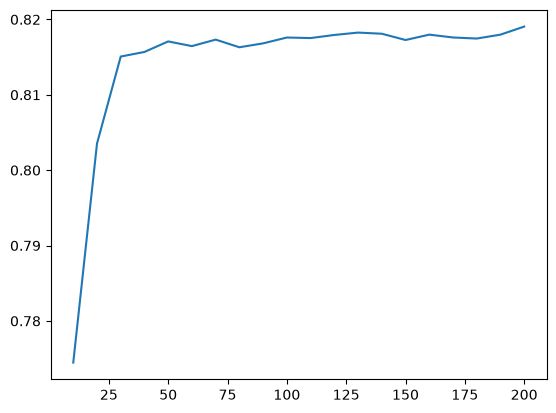

In [42]:
from matplotlib import pyplot as plt
plt.plot(df_scoresrf.n_estimators,df_scoresrf.auc)

In [43]:
scores=[]
for d in [5,10,15]:
    for n in range(10,201,10):
        rf=RandomForestClassifier(n_estimators=n,max_depth=d,random_state=1)
        rf.fit(X_train,y_train)
        y_pred=rf.predict_proba(X_val)[:,1]
        auc=roc_auc_score(y_val,y_pred)
        scores.append((d,n,auc))

In [44]:
df_scoresrf=pd.DataFrame(scores,columns=['max_depth','n_estimators','auc'])
df_scoresrf.sort_values(by='auc',ascending=False).head()

,max_depth,n_estimators,auc
35,10,160,0.825243
39,10,200,0.824923
37,10,180,0.824801
36,10,170,0.824632
38,10,190,0.824535


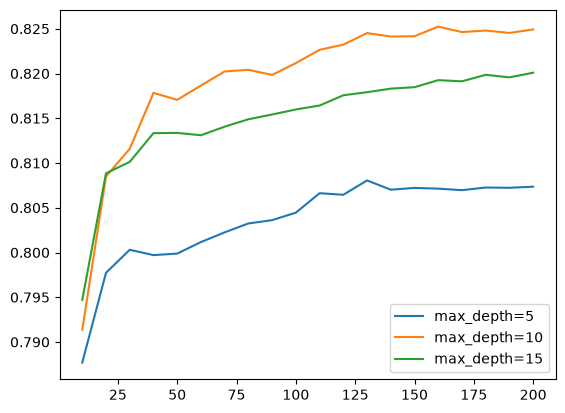

In [45]:
for d in [5,10,15]:
    df_subset=df_scoresrf[df_scoresrf.max_depth==d]
    plt.plot(df_subset.n_estimators,df_subset.auc,label=f'max_depth={d}')

plt.legend()

***the best depth is : 10***

In [46]:
scores=[]
for s in [1,3,5,10,15,50]:
    for n in range(10,201,10):
        rf=RandomForestClassifier(n_estimators=n,max_depth=10,min_samples_leaf=s,random_state=1,)
        rf.fit(X_train,y_train)
        y_pred=rf.predict_proba(X_val)[:,1]
        auc=roc_auc_score(y_val,y_pred)
        scores.append((s,n,auc))

KeyboardInterrupt: 

In [47]:
df_scoresrf=pd.DataFrame(scores,columns=['min_samples_leaf','n_estimators','auc'])
df_scoresrf.sort_values(by='auc',ascending=False)[:10]

,min_samples_leaf,n_estimators,auc
58,5,190,0.825952
35,3,160,0.825655
52,5,130,0.825286
37,3,180,0.825268
15,1,160,0.825243
55,5,160,0.825201
57,5,180,0.825171
38,3,190,0.825147
54,5,150,0.825031
33,3,140,0.825007


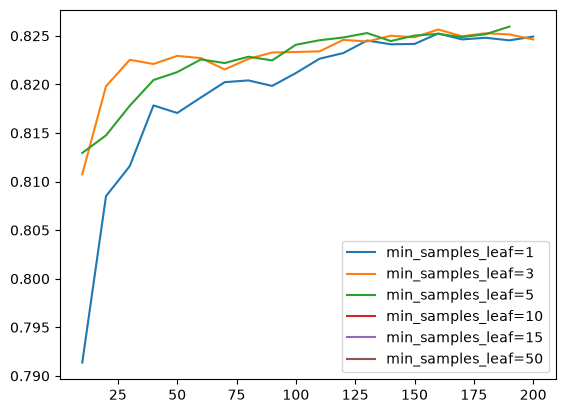

In [48]:
for d in [1,3,5,10,15,50]:
    df_subset=df_scoresrf[df_scoresrf.min_samples_leaf==d]
    plt.plot(df_subset.n_estimators,df_subset.auc,label=f'min_samples_leaf={d}')

plt.legend()

***the best min_samples_leaf : 5***

In [49]:
import xgboost as xgb

In [50]:
features=dv.feature_names_
dtrain= xgb.DMatrix(X_train,label=y_train,feature_names=features)
dval= xgb.DMatrix(X_val,label=y_val,feature_names=features)


In [57]:
xgb_params={
    'eta': 0.3,
    'max_depth':6,
    'min_child_weight':1,
    'objective':'binary:logistic',
    'nthread': 8,
    'seed':1,
    'verbosity':1,
}
model=xgb.train(xgb_params,dtrain,num_boost_round=200)

In [59]:
prob=model.predict(dval)

In [60]:
roc_auc_score(y_val,prob)

0.8045064299726334

In [61]:
whatchlist=[(dtrain,'train'),(dval,'val')]


In [117]:
%%capture output
xgb_params={
    'eta': 0.3,
    'max_depth':6,
    'min_child_weight':1,
    'eval_metric':'auc',
    'objective':'binary:logistic',
    'nthread': 8,
    'seed':1,
    'verbosity':1,
}
model=xgb.train(xgb_params,dtrain,num_boost_round=200,verbose_eval=5,evals=whatchlist)

In [ ]:
print(output.stdout)

[0]	train-auc:0.86632	val-auc:0.77998
[5]	train-auc:0.93359	val-auc:0.81150
[10]	train-auc:0.95391	val-auc:0.82002
[15]	train-auc:0.97087	val-auc:0.82220
[20]	train-auc:0.97677	val-auc:0.82239
[25]	train-auc:0.98440	val-auc:0.82074
[30]	train-auc:0.98805	val-auc:0.82061
[35]	train-auc:0.99239	val-auc:0.81804
[40]	train-auc:0.99474	val-auc:0.81732
[45]	train-auc:0.99627	val-auc:0.81413
[50]	train-auc:0.99753	val-auc:0.81320
[55]	train-auc:0.99811	val-auc:0.81140
[60]	train-auc:0.99893	val-auc:0.80818
[65]	train-auc:0.99924	val-auc:0.80696
[70]	train-auc:0.99955	val-auc:0.80710
[75]	train-auc:0.99979	val-auc:0.80802
[80]	train-auc:0.99987	val-auc:0.80813
[85]	train-auc:0.99993	val-auc:0.80761
[90]	train-auc:0.99995	val-auc:0.80782
[95]	train-auc:0.99997	val-auc:0.80870
[100]	train-auc:0.99999	val-auc:0.80839
[105]	train-auc:1.00000	val-auc:0.80735
[110]	train-auc:1.00000	val-auc:0.80730
[115]	train-auc:1.00000	val-auc:0.80779
[120]	train-auc:1.00000	val-auc:0.80570
[125]	train-auc:1.0000

In [ ]:
def parse_xgb_output(output:output):
    result=[]

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line=line.split('\t')

        it=int(it_line.strip('[]'))
        train=float(train_line.split(':')[1])
        val=float(val_line.split(':')[1])   

        result.append((it,train,val))
    columns=['num_iter','train_auc','val_auc']

    result=pd.DataFrame(result,columns=columns)


    return result

In [ ]:
df_scores=parse_xgb_output(output=output)

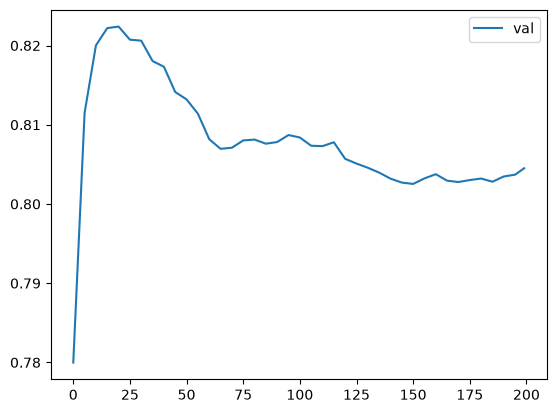

In [ ]:
# plt.plot(df_scores.num_iter,df_scores.train_auc,label='train')
plt.plot(df_scores.num_iter,df_scores.val_auc,label='val')
plt.legend()

In [152]:
scores={}

In [169]:
%%capture output
xgb_params={
    'eta': 0.01,
    'max_depth':6,
    'min_child_weight':1,
    'eval_metric':'auc',
    'objective':'binary:logistic',
    'nthread': 8,
    'seed':1,
    'verbosity':1,
}
model=xgb.train(xgb_params,dtrain,num_boost_round=200,verbose_eval=5,evals=whatchlist)

In [170]:
key='eta=%s' % (xgb_params['eta'])
scores[key]=parse_xgb_output(output=output)
key

'eta=0.01'

In [171]:
scores.keys()

dict_keys(['eta=0.3', 'eta=1.0', 'eta=0.1', 'eta=0.05', 'eta=0.01'])

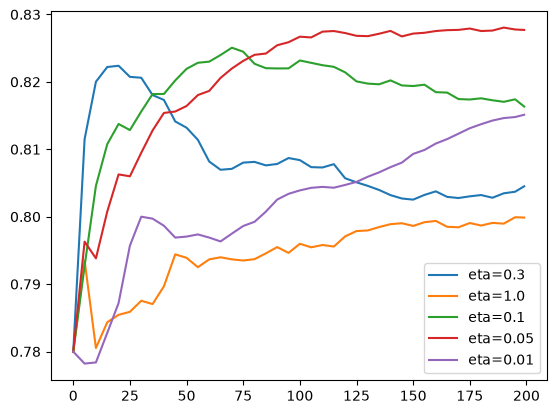

In [173]:
for key,df_scores in scores.items():
    plt.plot(df_scores.num_iter,df_scores.val_auc,label=key)
plt.legend()

In [196]:
scores={}

In [ ]:
%%capture output
xgb_params={
    'eta': 0.1,
    'max_depth':3,
    'min_child_weight':1,
    'eval_metric':'auc',
    'objective':'binary:logistic',
    'nthread': 8,
    'seed':1,
    'verbosity':1,
}
model=xgb.train(xgb_params,dtrain,num_boost_round=200,verbose_eval=5,evals=whatchlist)

In [207]:
key='max_depth=%s' % (xgb_params['max_depth'])
scores[key]=parse_xgb_output(output=output)
key

'max_depth=6'

In [208]:
scores.keys()

dict_keys(['max_depth=10', 'max_depth=3', 'max_depth=4', 'max_depth=6'])

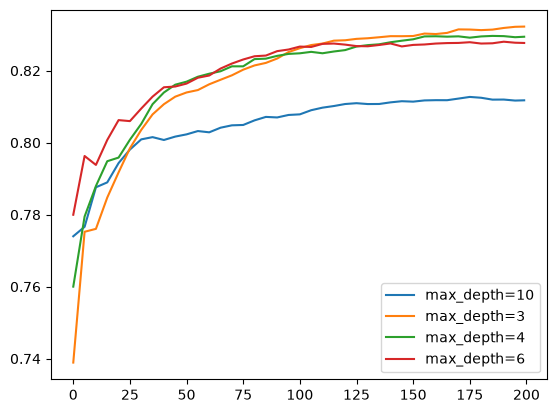

In [209]:
for key,df_scores in scores.items():
    plt.plot(df_scores.num_iter,df_scores.val_auc,label=key)
plt.legend()

In [210]:
scores={}

In [220]:
%%capture output
xgb_params={
    'eta': 0.1,
    'max_depth':3,
    'min_child_weight':30,
    'eval_metric':'auc',
    'objective':'binary:logistic',
    'nthread': 8,
    'seed':1,
    'verbosity':1,
}
model=xgb.train(xgb_params,dtrain,num_boost_round=200,verbose_eval=5,evals=whatchlist)

In [221]:
key='min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key]=parse_xgb_output(output=output)
key

'min_child_weight=30'

In [222]:
scores.keys()

dict_keys(['min_child_weight=1', 'min_child_weight=10', 'min_child_weight=30'])

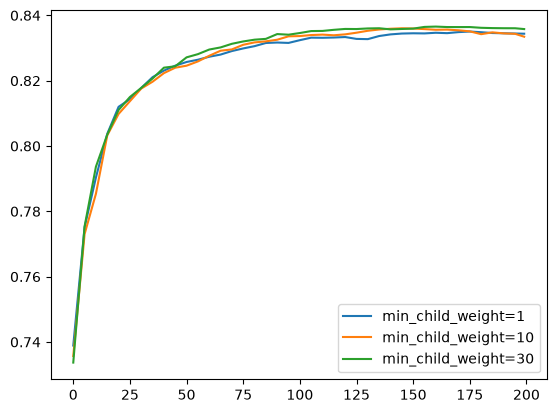

In [223]:
for key,df_scores in scores.items():
    plt.plot(df_scores.num_iter,df_scores.val_auc,label=key)
plt.legend()